# 2. Modélisation

**Entrée :** `data/batiments_cible.csv` (notebook d'analyse exploratoire).

### Import des modules 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv("data/batiments_cible.csv")
cible = "SiteEnergyUse(kBtu)"
print(df.shape)

(1481, 19)


### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

Le nettoyage, le feature engineering, la corrélation et les transformations sont faits dans le notebook 1. Ici, il reste à séparer X et y, puis à encoder.

#### Séparation X / y

In [3]:
# X = les infos du bâtiment, sans l'autre cible (CO2) ni l'ENERGY STAR Score (testé à la fin)
X = df.drop(columns=[cible, "TotalGHGEmissions", "ENERGYSTARScore"])
# y = la conso en log10 (6 = 1 million de kBtu), voir la distribution dans le notebook 1
y = np.log10(df[cible])

# 80 % pour entraîner, 20 % gardés de côté pour le test final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train :", X_train.shape, " test :", X_test.shape)

train : (1184, 16)  test : (297, 16)


#### Encodage et mise à l'échelle

Les colonnes texte passent dans un `OneHotEncoder` (une colonne 0/1 par catégorie). Avec `handle_unknown="ignore"`, on évite une erreur si une catégorie rare n'apparaît que dans le test.

Je n'ai pas pris le `LabelEncoder` parce qu'il transforme les catégories en 1, 2, 3… et le modèle penserait qu'il y a un ordre entre les quartiers ou les usages.

Les colonnes numériques passent dans un `StandardScaler` pour être à la même échelle, ce qui est nécessaire pour le SVR et la régression linéaire.

Je mets ce préprocesseur dans un `Pipeline` avec chaque modèle. Comme ça, l'encodage et le scaling sont calculés seulement sur la partie entraînement à chaque tour de la validation croisée. Sinon, une partie de l'info du test passerait dans l'entraînement.

In [4]:
colonnes_texte = X.select_dtypes(exclude="number").columns.tolist()
colonnes_nombres = X.select_dtypes("number").columns.tolist()
print("texte :", colonnes_texte)
print("nombres :", colonnes_nombres)

preprocesseur = ColumnTransformer([
    ("texte", OneHotEncoder(handle_unknown="ignore"), colonnes_texte),
    ("nombres", StandardScaler(), colonnes_nombres),
])

# vérification : combien de colonnes après encodage ?
print(preprocesseur.fit_transform(X_train).shape)

texte : ['PrimaryPropertyType', 'Neighborhood', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'Periode']
nombres : ['NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'UtiliseGaz', 'UtiliseVapeur', 'PartParking', 'NbUsages']
(1184, 180)


### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [5]:
modeles = {
    "Dummy": DummyRegressor(),
    "Régression linéaire": LinearRegression(),
    "SVR": SVR(),
    "RandomForest": RandomForestRegressor(random_state=42),
}

# sklearn renvoie les erreurs en négatif (plus c'est grand, mieux c'est), on remettra le signe
metriques = {"R2": "r2", "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}

resultats = []
for nom, modele in modeles.items():
    pipe = Pipeline([("preprocesseur", preprocesseur), ("modele", modele)])
    # validation croisée en 5 plis, sur le jeu d'entraînement seulement
    scores = cross_validate(pipe, X_train, y_train, cv=5, scoring=metriques, return_train_score=True)
    resultats.append({
        "modèle": nom,
        "R2 train": scores["train_R2"].mean(),
        "R2 validation": scores["test_R2"].mean(),
        "MAE train": -scores["train_MAE"].mean(),
        "MAE validation": -scores["test_MAE"].mean(),
        "RMSE train": -scores["train_RMSE"].mean(),
        "RMSE validation": -scores["test_RMSE"].mean(),
        "temps (s)": scores["fit_time"].mean(),
    })

pd.DataFrame(resultats).round(3)

,modèle,R2 train,R2 validation,MAE train,MAE validation,RMSE train,RMSE validation,temps (s)
0,Dummy,0.000,-0.005,0.443,0.444,0.556,0.556,0.006
1,Régression linéaire,0.811,0.708,0.182,0.227,0.242,0.299,0.014
2,SVR,0.883,0.730,0.139,0.217,0.191,0.287,0.037
3,RandomForest,0.960,0.714,0.082,0.221,0.111,0.296,1.106


Les 3 modèles font beaucoup mieux que le Dummy (R² proche de 0), donc ils apprennent bien quelque chose.

Le SVR est le meilleur en validation (R² = 0,73 et MAE = 0,22). Une MAE de 0,22 en log10 veut dire qu'on se trompe en général d'un facteur 1,7 environ sur la consommation.

Le RandomForest sur-apprend : 0,96 en train mais 0,71 en validation. La régression linéaire est juste derrière avec 0,71.

Je garde donc le SVR pour l'optimisation.

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

#### GridSearch sur le SVR

Les 3 hyperparamètres testés :
- `C` : plus il est grand, plus le modèle colle aux données d'entraînement (risque de sur-apprentissage) ;
- `gamma` : plus il est grand, plus la courbe peut être tordue ;
- `epsilon` : l'erreur qu'on tolère sans pénalité.

In [6]:
pipe_svr = Pipeline([("preprocesseur", preprocesseur), ("modele", SVR())])

# "modele__" = le paramètre appartient à l'étape "modele" du pipeline
grille = {
    "modele__C": [1, 10, 100],
    "modele__gamma": ["scale", 0.01, 0.001],
    "modele__epsilon": [0.1, 0.2],
}

grid = GridSearchCV(pipe_svr, grille, cv=5, scoring="r2", return_train_score=True)
grid.fit(X_train, y_train)

print("meilleurs paramètres :", grid.best_params_)
print("R2 validation :", round(grid.best_score_, 3))
print("R2 train :", round(grid.cv_results_["mean_train_score"][grid.best_index_], 3))

meilleurs paramètres : {'modele__C': 100, 'modele__epsilon': 0.2, 'modele__gamma': 0.001}
R2 validation : 0.739
R2 train : 0.809


Le GridSearch améliore un peu le score (0,73 → 0,74) et l'écart entre train et validation diminue (0,81 contre 0,74).

#### Évaluation finale sur le jeu de test

Je n'ai pas touché au jeu de test jusqu'ici, c'est lui qui donne la vraie performance du modèle.

In [7]:
y_pred = grid.predict(X_test)

print("R2 test :", round(r2_score(y_test, y_pred), 3))
print("MAE test :", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

R2 test : 0.781
MAE test : 0.215
RMSE test : 0.283


R² = 0,78 sur le test, proche de la validation (0,74), donc le modèle marche aussi sur des bâtiments qu'il n'a jamais vus. Il explique environ 78 % des variations de consommation (en log) avec seulement des informations connues sans compteur.

#### Variables les plus importantes : permutation importance

Le SVR n'a pas de `feature_importances_` (c'est pour les modèles à arbres), donc j'utilise la permutation importance. On mélange une colonne à la fois dans le jeu de test et on regarde de combien le R² baisse. Comme je le calcule sur le pipeline complet, on obtient l'importance des 16 colonnes de départ et pas des colonnes après encodage.

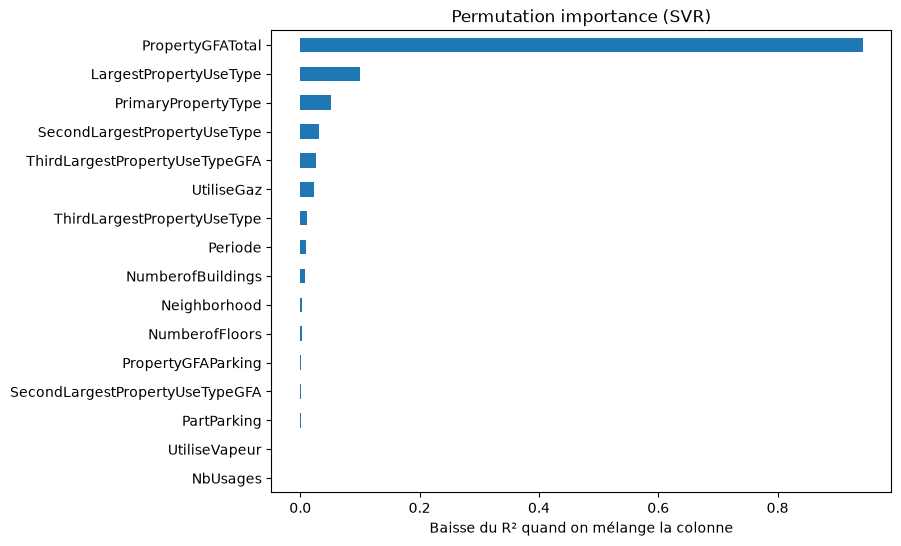

PropertyGFATotal                   0.944
LargestPropertyUseType             0.101
PrimaryPropertyType                0.052
SecondLargestPropertyUseType       0.031
ThirdLargestPropertyUseTypeGFA     0.026
UtiliseGaz                         0.023
ThirdLargestPropertyUseType        0.012
Periode                            0.010
NumberofBuildings                  0.008
Neighborhood                       0.003
NumberofFloors                     0.003
PropertyGFAParking                 0.002
SecondLargestPropertyUseTypeGFA    0.002
PartParking                        0.001
UtiliseVapeur                      0.000
NbUsages                          -0.001
dtype: float64

In [8]:
# 10 mélanges par colonne pour lisser le hasard
perm = permutation_importance(grid, X_test, y_test, n_repeats=10, scoring="r2", random_state=42)

importances = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 6))
importances.plot(kind="barh")
plt.xlabel("Baisse du R² quand on mélange la colonne")
plt.title("Permutation importance (SVR)")
plt.show()

importances.sort_values(ascending=False).round(3)

La surface totale est de loin la plus importante : quand on la mélange, le R² baisse d'environ 0,94 et le modèle ne sait presque plus rien prédire. Ensuite viennent les usages (environ 0,10 pour l'usage principal et 0,05 pour le type de bâtiment) : à surface égale, un hôpital et un entrepôt ne consomment pas pareil. Le gaz compte un peu (0,02), la période très peu (0,01).

La vapeur ne compte presque pas, alors que sur le boxplot les bâtiments raccordés consommaient 3,5 fois plus. Comme pour la période, c'est en fait la surface qui expliquait cet écart.

En résumé, pour prédire la consommation d'un bâtiment non résidentiel à Seattle, il faut surtout connaître sa surface, puis son usage.

#### Test : le modèle avec `ENERGYSTARScore`

J'avais mis ce score de côté en créant X. Je le remets ici pour voir ce qu'il apporte, avec le même SVR. Pour les 35 % de cases vides, je mets la médiane calculée sur le jeu d'entraînement.

In [9]:
score_es = df["ENERGYSTARScore"]

X_train_es = X_train.copy()
X_test_es = X_test.copy()
X_train_es["ENERGYSTARScore"] = score_es[X_train.index]
X_test_es["ENERGYSTARScore"] = score_es[X_test.index]

# médiane calculée sur le train seulement
mediane = X_train_es["ENERGYSTARScore"].median()
X_train_es["ENERGYSTARScore"] = X_train_es["ENERGYSTARScore"].fillna(mediane)
X_test_es["ENERGYSTARScore"] = X_test_es["ENERGYSTARScore"].fillna(mediane)

In [10]:
preprocesseur_es = ColumnTransformer([
    ("texte", OneHotEncoder(handle_unknown="ignore"), colonnes_texte),
    ("nombres", StandardScaler(), colonnes_nombres + ["ENERGYSTARScore"]),
])

# même SVR que le GridSearch
pipe_es = Pipeline([("preprocesseur", preprocesseur_es), ("modele", SVR())])
pipe_es.set_params(**grid.best_params_)

scores_es = cross_validate(pipe_es, X_train_es, y_train, cv=5, scoring="r2")
pipe_es.fit(X_train_es, y_train)

print("sans le score : R2 validation", round(grid.best_score_, 3), "| R2 test", round(r2_score(y_test, y_pred), 3))
print("avec le score : R2 validation", round(scores_es["test_score"].mean(), 3), "| R2 test", round(r2_score(y_test, pipe_es.predict(X_test_es)), 3))

sans le score : R2 validation 0.739 | R2 test 0.781
avec le score : R2 validation 0.783 | R2 test 0.838


Avec le score, le modèle est meilleur (R² de validation de 0,74 à 0,78, et de 0,78 à 0,84 sur le test).

Je ne le garde quand même pas dans le modèle final. Le score ENERGY STAR est calculé à partir de la consommation mesurée, donc c'est en partie la réponse (fuite de données). Et pour un bâtiment qui n'a jamais été mesuré, la ville n'a pas ce score, donc le modèle ne servirait à rien. En plus, il manque déjà pour 35 % des bâtiments.

Le modèle final reste donc le SVR sans le score, avec un R² de 0,78 sur le test.